### Read me

xxxxxx

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

### Load dataset

In [2]:
df = pd.read_csv("raw_data/spotify-tracks-dataset-detailed.csv")

df.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [3]:
len(df)

114000

In [4]:
# 1. limpeza
mask = (
    (df.tempo > 0) & (df.time_signature > 0) & (df.duration_ms > 0)
    & (df.danceability > 0) & (df.energy > 0)
)
df = df[mask].copy()
len(df)

113836

### Pre processing

In [5]:
def preprocessing(df):

    df = df.copy()

    features = [
        "danceability",
        "energy",
        "loudness",
        "speechiness",
        "acousticness",
        "instrumentalness",
        "valence",
        "tempo"
    ]

    metadata = [
        "track_id",
        "artists",
        "track_name"
    ]

    # 1. Remover comedy
    df = df[df["track_genre"] != "comedy"].copy()

    # 2. Selecionar colunas necessárias
    df = df[metadata + ["track_genre"] + features]

    # 3. Remover valores nulos
    df = df.dropna(subset=metadata + features)

    # 4. Remover duplicatas exatas
    df = df.drop_duplicates()

    # 5. Preservar todos os gêneros de cada música
    genres = (
        df.groupby("track_id")["track_genre"]
        .agg(lambda x: sorted(set(x)))
    )

    # 6. Manter uma linha por música
    df = df.drop_duplicates(subset=["track_id"]).copy()

    # 7. Adicionar gêneros associados
    df["genres"] = df["track_id"].map(genres)

    # 8. Separar metadados e features
    df_metadata = df[metadata + ["genres"]].reset_index(drop=True)
    X = df[features].reset_index(drop=True)

    # 9. Escalonar features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X) # Se for separar entre treino e teste precisa fazer o fit só p/ dados de treino

    return X_scaled, df_metadata, scaler


In [6]:
X_scaled, df_metadata, scaler = preprocessing(df)

In [7]:
df_metadata.head()

,track_id,artists,track_name,genres
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,"[acoustic, j-pop, singer-songwriter, songwriter]"
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost - Acoustic,"[acoustic, chill]"
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,[acoustic]
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Can't Help Falling In Love,[acoustic]
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,[acoustic]


In [8]:
X_scaled

array([[ 0.64249579, -0.67749445,  0.32956539, ..., -0.53791417,
         0.93026192, -1.16741153],
       [-0.81305821, -1.82853155, -1.69592746, ..., -0.53790014,
        -0.77420189, -1.51931019],
       [-0.71071457, -1.07548016, -0.24743648, ..., -0.53791728,
        -1.33347907, -1.5583538 ],
       ...,
       [ 0.37526517, -1.19253478, -0.47163299, ..., -0.53791728,
         1.03679091,  0.33294964],
       [ 0.13646334, -0.50191251, -0.47047435, ..., -0.53791728,
        -0.21872931,  0.45382622],
       [-0.21036789, -0.57604711, -0.33819648, ..., -0.53791728,
         0.90362967, -1.46163903]], shape=(88589, 8))

In [9]:
df_scaled = pd.DataFrame(
    X_scaled,
    columns=[
        "danceability",
        "energy",
        "loudness",
        "speechiness",
        "acousticness",
        "instrumentalness",
        "valence",
        "tempo"
    ]
)

df_scaled.head()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,valence,tempo
0,0.642496,-0.677494,0.329565,0.759749,-0.865732,-0.537914,0.930262,-1.167412
1,-0.813058,-1.828532,-1.695927,-0.045718,1.784477,-0.537900,-0.774202,-1.519310
2,-0.710715,-1.075480,-0.247436,-0.294483,-0.337354,-0.537917,-1.333479,-1.558354
3,-1.688665,-2.243685,-1.943104,-0.528756,1.728014,-0.537699,-1.245973,1.998698
4,0.312722,-0.747727,-0.237202,-0.331918,0.432330,-0.537917,-1.154663,-0.086474


In [10]:
df_final = pd.concat([df_metadata, df_scaled], axis=1)

df_final.head()

,track_id,artists,track_name,genres,danceability,energy,loudness,speechiness,acousticness,instrumentalness,valence,tempo
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,"[acoustic, j-pop, singer-songwriter, songwriter]",0.642496,-0.677494,0.329565,0.759749,-0.865732,-0.537914,0.930262,-1.167412
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost - Acoustic,"[acoustic, chill]",-0.813058,-1.828532,-1.695927,-0.045718,1.784477,-0.537900,-0.774202,-1.519310
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,[acoustic],-0.710715,-1.075480,-0.247436,-0.294483,-0.337354,-0.537917,-1.333479,-1.558354
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Can't Help Falling In Love,[acoustic],-1.688665,-2.243685,-1.943104,-0.528756,1.728014,-0.537699,-1.245973,1.998698
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,[acoustic],0.312722,-0.747727,-0.237202,-0.331918,0.432330,-0.537917,-1.154663,-0.086474


**Considerações sobre as features**

- Energy, loudness e acousticness são fortemente correlacionadas e pesam como um único eixo de "intensidade" na distância do K-Means.
- Speechiness, instrumentalness e acousticness têm distribuição muito assimétrica, e loudness e duration têm outliers. Isso afeta o `StandardScaler`.

### DBSCAN

In [11]:
features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "valence",
    "tempo"
]

X = df_final[features]

In [12]:
# Instanciando o modelo
dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)

# Treinando e atribuindo os clusters
y_pred_dbscan = dbscan.fit_predict(X)


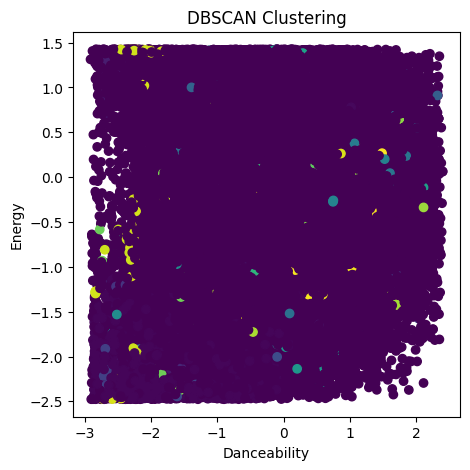

In [13]:
plt.figure(figsize=(5, 5))

plt.scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=y_pred_dbscan
)

plt.title("DBSCAN Clustering")
plt.xlabel("Danceability")
plt.ylabel("Energy")
plt.show()

### K-Distance Plot

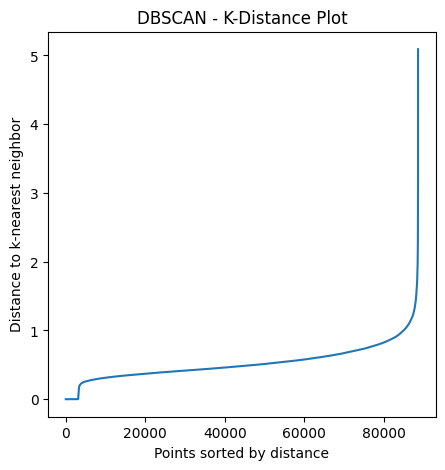

In [14]:
min_samples = 5

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X)

distances, indices = neighbors_fit.kneighbors(X)

# Distância até o k-ésimo vizinho
distances = np.sort(distances[:, -1])

plt.figure(figsize=(5, 5))
plt.plot(distances)

plt.title("DBSCAN - K-Distance Plot")
plt.xlabel("Points sorted by distance")
plt.ylabel("Distance to k-nearest neighbor")
plt.show()

### Silhouette Score

In [15]:

from sklearn.utils import resample

# Amostra de 10 mil músicas
X_sample = X.sample(n=10000, random_state=42)

results = []

for eps in [0.5, 0.7, 0.9, 1.1, 1.3, 1.5]:

    model = DBSCAN(eps=eps, min_samples=5)
    labels = model.fit_predict(X_sample)

    mask = labels != -1
    n_clusters = len(set(labels[mask]))
    noise = (labels == -1).mean() * 100

    score = None

    if n_clusters >= 2:
        score = silhouette_score(X_sample[mask], labels[mask])

    results.append({
        'eps': eps,
        'clusters': n_clusters,
        'noise_pct': noise,
        'silhouette': score
    })

print(pd.DataFrame(results))

   eps  clusters  noise_pct  silhouette
0  0.5       101      75.14   -0.202465
1  0.7        32      35.11   -0.280775
2  0.9        14      16.21   -0.055419
3  1.1         4       6.32    0.215219
4  1.3         5       2.62    0.178095
5  1.5         2       1.37    0.336305
